<a href="https://colab.research.google.com/github/davidfwallace/metastase-pcam/blob/main/notebooks/04_modelo_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 04 — Modelo final e avaliação no teste

Modelo escolhido no notebook 03: `C_fine_tuning_3ep` (ResNet-18 pré-treinada, fine-tuning de 3 épocas,
AUC de validação 0,959 ± 0,001 em 3 sementes).

Tudo o que pode ser decidido é decidido **na validação**: ensemble ou modelo único, TTA e limiar de operação.
As expectativas são registradas antes, e o **teste é aberto uma única vez**, no fim.

In [1]:
import subprocess
import sys
import time
from pathlib import Path

import numpy as np
import psutil
import torch

print("GPU:", torch.cuda.get_device_name(0))

# Código do projeto: clona na primeira vez, atualiza nas seguintes
REPO = Path("/content/metastase-pcam")
if REPO.exists():
    subprocess.run(["git", "-C", str(REPO), "pull"], check=True)
else:
    subprocess.run(["git", "clone", "https://github.com/davidfwallace/metastase-pcam.git", str(REPO)],
                   check=True)
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

from google.colab import drive
drive.mount("/content/drive")

RAIZ = Path("/content/drive/MyDrive/metastase-pcam")
DATA_DIR = RAIZ / "data"
REPORTS_DIR = RAIZ / "reports"
CACHE_DIR = Path("/content/cache")

def ram_livre():
    return psutil.virtual_memory().available / 1e9

print(f"RAM total: {psutil.virtual_memory().total / 1e9:.1f} GB | livre: {ram_livre():.1f} GB")

GPU: Tesla T4
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
RAM total: 13.6 GB | livre: 11.1 GB


In [2]:
from sklearn.metrics import roc_auc_score

from src.dados import para_ram_se_couber, preparar_split
from src.dataset import carregador
from src.modelos import ResNetPCam
from src.treino import prever

X_valid_mm, y_valid = preparar_split(DATA_DIR, "valid", CACHE_DIR)
X_valid = para_ram_se_couber(X_valid_mm)
carregador_valid = carregador(X_valid, y_valid, 256, embaralhar=False)

FINAL = "C_fine_tuning_3ep"
SEMENTES = (0, 1, 2)

def carregar_modelo(semente):
    """Pesos da ÚLTIMA época (ultimo.pt) — o mesmo critério da comparação do notebook 03."""
    estado = torch.load(RAIZ / "checkpoints" / f"{FINAL}_s{semente}" / "ultimo.pt",
                        map_location="cuda", weights_only=True)
    modelo = ResNetPCam(pretreinada=False).cuda()  # a arquitetura; os pesos vêm do checkpoint
    modelo.load_state_dict(estado["modelo"])
    return modelo.eval()

logits_valid = {}
for semente in SEMENTES:
    logits_valid[semente], _ = prever(carregar_modelo(semente), carregador_valid)
    print(f"Semente {semente}: AUC {roc_auc_score(y_valid, logits_valid[semente]):.4f}")

logits_ensemble = np.mean([logits_valid[s] for s in SEMENTES], axis=0)
print(f"Ensemble (média dos logits): AUC {roc_auc_score(y_valid, logits_ensemble):.4f}")

Semente 0: AUC 0.9602
Semente 1: AUC 0.9589
Semente 2: AUC 0.9584
Ensemble (média dos logits): AUC 0.9636


In [3]:
logits_valid_tta = {}
for semente in SEMENTES:
    logits_valid_tta[semente], _ = prever(carregar_modelo(semente), carregador_valid, tta=True)

combinacoes = {
    "Modelo único (média das 3 sementes)": np.mean([roc_auc_score(y_valid, logits_valid[s]) for s in SEMENTES]),
    "Modelo único + TTA": np.mean([roc_auc_score(y_valid, logits_valid_tta[s]) for s in SEMENTES]),
    "Ensemble": roc_auc_score(y_valid, logits_ensemble),
    "Ensemble + TTA": roc_auc_score(y_valid, np.mean([logits_valid_tta[s] for s in SEMENTES], axis=0)),
}
for nome, auc in combinacoes.items():
    print(f"{nome:38s} AUC {auc:.4f}")

Modelo único (média das 3 sementes)    AUC 0.9592
Modelo único + TTA                     AUC 0.9652
Ensemble                               AUC 0.9636
Ensemble + TTA                         AUC 0.9673


In [4]:
from sklearn.metrics import roc_curve

def sigmoide(z):
    return 1 / (1 + np.exp(-z))

logits_final_valid = np.mean([logits_valid_tta[s] for s in SEMENTES], axis=0)
fpr, tpr, limiares = roc_curve(y_valid, logits_final_valid)

SENSIBILIDADE_ALVO = 0.95  # decidido antes de ver a tabela
print("Limiar  | prob.  | sensibilidade | especificidade")
for alvo in (0.90, SENSIBILIDADE_ALVO, 0.98):
    i = np.argmax(tpr >= alvo)  # o maior limiar que alcança o alvo
    marca = "  <- escolhido" if alvo == SENSIBILIDADE_ALVO else ""
    print(f"{limiares[i]:7.3f} | {sigmoide(limiares[i]):.4f} | {tpr[i]:13.3f} | {1 - fpr[i]:14.3f}{marca}")

LIMIAR = limiares[np.argmax(tpr >= SENSIBILIDADE_ALVO)]

# Para comparar: o limiar padrão (probabilidade 0,5, ou seja, logit 0)
previsto = logits_final_valid >= 0
print(f"\nLimiar padrão 0,5: sensibilidade {previsto[y_valid == 1].mean():.3f} | "
      f"especificidade {(~previsto[y_valid == 0]).mean():.3f}")

Limiar  | prob.  | sensibilidade | especificidade
 -2.094 | 0.1097 |         0.900 |          0.915
 -3.415 | 0.0318 |         0.950 |          0.819  <- escolhido
 -4.652 | 0.0094 |         0.980 |          0.645

Limiar padrão 0,5: sensibilidade 0.799 | especificidade 0.976


In [5]:
import json

decisoes = {
    "modelo": FINAL,
    "sementes": list(SEMENTES),
    "checkpoint": "ultimo.pt (última época)",
    "ensemble": "média dos logits das 3 sementes",
    "tta": "média dos logits nas 8 simetrias do quadrado",
    "sensibilidade_alvo_valid": SENSIBILIDADE_ALVO,
    "limiar_logit": float(LIMIAR),
    "limiar_probabilidade": float(sigmoide(LIMIAR)),
    "auc_valid": float(roc_auc_score(y_valid, logits_final_valid)),
}

MODELS_DIR = RAIZ / "models"
MODELS_DIR.mkdir(exist_ok=True)
caminho_decisoes = MODELS_DIR / "decisoes_pre_teste.json"
if caminho_decisoes.exists():
    print("Decisões já congeladas: o arquivo existente não é sobrescrito.")
else:
    with open(caminho_decisoes, "w", encoding="utf-8") as arquivo:
        json.dump(decisoes, arquivo, indent=2, ensure_ascii=False)
print(json.dumps(decisoes, indent=2, ensure_ascii=False))

Decisões já congeladas: o arquivo existente não é sobrescrito.
{
  "modelo": "C_fine_tuning_3ep",
  "sementes": [
    0,
    1,
    2
  ],
  "checkpoint": "ultimo.pt (última época)",
  "ensemble": "média dos logits das 3 sementes",
  "tta": "média dos logits nas 8 simetrias do quadrado",
  "sensibilidade_alvo_valid": 0.95,
  "limiar_logit": -3.4147136211395264,
  "limiar_probabilidade": 0.03183877840638161,
  "auc_valid": 0.9673314342259344
}


## Pré-registro (escrito antes de abrir o teste)

**Decisões congeladas** em `models/decisoes_pre_teste.json`: ensemble das 3 sementes de `C_fine_tuning_3ep` (última época), TTA nas 8 simetrias, limiar em logit −3,415 (probabilidade 0,032), escolhido para sensibilidade de 95% na validação.

**O que esperamos no teste:**
- **AUC entre 0,93 e 0,97**, mais provavelmente um pouco abaixo dos 0,967 da validação: todas as escolhas (épocas, ensemble, TTA) foram feitas na validação, o que a deixa otimista, e o teste vem de outras lâminas.
- **Sensibilidade no limiar abaixo de 0,95**, provavelmente entre 0,88 e 0,95, pelo mesmo motivo: um limiar escolhido numa amostra rende menos em outra. Especificidade em torno de 0,80.
- **Ensemble + TTA melhor que o modelo único** também no teste.

**O que vamos reportar, qualquer que seja o resultado:** AUC, sensibilidade e especificidade no limiar escolhido e no limiar padrão de 0,5, com intervalos de confiança.

**Também reportamos, como contexto (sem mudar nenhuma decisão):** as quatro combinações (modelo único, modelo único + TTA, ensemble, ensemble + TTA), a log-loss, a acurácia nos dois limiares e a CNN pequena do notebook 02 (última época), para verificar se o ganho do transfer learning se mantém no teste. **Esperamos a CNN pequena abaixo do modelo final também no teste.**

In [6]:
import torch.nn.functional as F

from src.modelos import CNNPequena

def wilson(acertos, n, z=1.96):
    """Intervalo de confiança de 95% para uma proporção (Wilson)."""
    p = acertos / n
    denominador = 1 + z**2 / n
    centro = (p + z**2 / (2 * n)) / denominador
    margem = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denominador
    return centro - margem, centro + margem

with open(MODELS_DIR / "decisoes_pre_teste.json", encoding="utf-8") as arquivo:
    congeladas = json.load(arquivo)  # tudo vem do arquivo, nada da memória
sementes = congeladas["sementes"]

X_teste_mm, y_teste = preparar_split(DATA_DIR, "test", CACHE_DIR)
X_teste = para_ram_se_couber(X_teste_mm)
carregador_teste = carregador(X_teste, y_teste, 256, embaralhar=False)

# Previsões: as 3 sementes, sem e com TTA
logits_teste, logits_teste_tta = {}, {}
for semente in sementes:
    modelo = carregar_modelo(semente)
    logits_teste[semente], _ = prever(modelo, carregador_teste)
    logits_teste_tta[semente], _ = prever(modelo, carregador_teste, tta=True)
logits_final_teste = np.mean([logits_teste_tta[s] for s in sementes], axis=0)

# A CNN pequena do notebook 02 (última época), como referência
cnn = CNNPequena().cuda()
cnn.load_state_dict(torch.load(RAIZ / "checkpoints" / "cnn_pequena" / "ultimo.pt",
                               map_location="cuda", weights_only=True)["modelo"])
logits_cnn_teste, _ = prever(cnn, carregador_teste)

# Métricas
alvos = torch.from_numpy(y_teste.astype(np.float32))

def auc_e_perda(logits):
    perda = F.binary_cross_entropy_with_logits(torch.from_numpy(logits), alvos).item()
    return {"auc": float(roc_auc_score(y_teste, logits)), "log_loss": perda}

def media_das_sementes(lista_de_logits):
    resultados = [auc_e_perda(l) for l in lista_de_logits]
    return {chave: float(np.mean([r[chave] for r in resultados])) for chave in ("auc", "log_loss")}

combinacoes = {
    "Modelo único (média das sementes)": media_das_sementes([logits_teste[s] for s in sementes]),
    "Modelo único + TTA": media_das_sementes([logits_teste_tta[s] for s in sementes]),
    "Ensemble": auc_e_perda(np.mean([logits_teste[s] for s in sementes], axis=0)),
    "Ensemble + TTA (modelo final)": auc_e_perda(logits_final_teste),
    "CNN pequena (02, última época)": auc_e_perda(logits_cnn_teste),
}

# Intervalo de confiança da AUC do modelo final (bootstrap por imagem: otimista, ver o texto)
sorteio = np.random.default_rng(0)
n = len(y_teste)
aucs_bootstrap = [roc_auc_score(y_teste[i], logits_final_teste[i])
                  for i in (sorteio.integers(0, n, n) for _ in range(1000))]
auc_inf, auc_sup = np.percentile(aucs_bootstrap, [2.5, 97.5])

print(f"Teste: {n:,} imagens, fração positiva {np.mean(y_teste):.3f}\n")
for nome, m in combinacoes.items():
    print(f"{nome:34s} AUC {m['auc']:.4f} | log-loss {m['log_loss']:.3f}")
print(f"\nAUC do modelo final: IC 95% de {auc_inf:.4f} a {auc_sup:.4f}")

positivos, negativos = y_teste == 1, y_teste == 0
por_limiar = {}
for nome, limiar in [("escolhido (sensib. 95% na validação)", congeladas["limiar_logit"]),
                     ("padrão (probabilidade 0,5)", 0.0)]:
    previsto = logits_final_teste >= limiar
    vp, vn = int(previsto[positivos].sum()), int((~previsto[negativos]).sum())
    por_limiar[nome] = {
        "sensibilidade": vp / int(positivos.sum()), "sensibilidade_ic95": wilson(vp, int(positivos.sum())),
        "especificidade": vn / int(negativos.sum()), "especificidade_ic95": wilson(vn, int(negativos.sum())),
        "acuracia": float(np.mean(previsto == positivos)),
    }
    r = por_limiar[nome]
    print(f"\nLimiar {nome}:")
    print(f"  sensibilidade  {r['sensibilidade']:.3f} (IC 95%: {r['sensibilidade_ic95'][0]:.3f} a {r['sensibilidade_ic95'][1]:.3f})")
    print(f"  especificidade {r['especificidade']:.3f} (IC 95%: {r['especificidade_ic95'][0]:.3f} a {r['especificidade_ic95'][1]:.3f})")
    print(f"  acurácia       {r['acuracia']:.3f}")

# Salvar tudo, para não depender da sessão
resultado = {"decisoes": congeladas, "combinacoes": combinacoes,
             "auc_final_ic95_bootstrap_por_imagem": [float(auc_inf), float(auc_sup)],
             "por_limiar": por_limiar}
with open(REPORTS_DIR / "04_resultado_teste.json", "w", encoding="utf-8") as arquivo:
    json.dump(resultado, arquivo, indent=2, ensure_ascii=False, default=float)
np.save(REPORTS_DIR / "04_logits_teste.npy", logits_final_teste)
print("\nSalvo: 04_resultado_teste.json e 04_logits_teste.npy")

Teste: 32,768 imagens, fração positiva 0.500

Modelo único (média das sementes)  AUC 0.9390 | log-loss 0.507
Modelo único + TTA                 AUC 0.9469 | log-loss 0.489
Ensemble                           AUC 0.9463 | log-loss 0.482
Ensemble + TTA (modelo final)      AUC 0.9510 | log-loss 0.476
CNN pequena (02, última época)     AUC 0.9318 | log-loss 0.501

AUC do modelo final: IC 95% de 0.9485 a 0.9530

Limiar escolhido (sensib. 95% na validação):
  sensibilidade  0.911 (IC 95%: 0.907 a 0.915)
  especificidade 0.829 (IC 95%: 0.823 a 0.835)
  acurácia       0.870

Limiar padrão (probabilidade 0,5):
  sensibilidade  0.690 (IC 95%: 0.682 a 0.697)
  especificidade 0.980 (IC 95%: 0.978 a 0.982)
  acurácia       0.835

Salvo: 04_resultado_teste.json e 04_logits_teste.npy


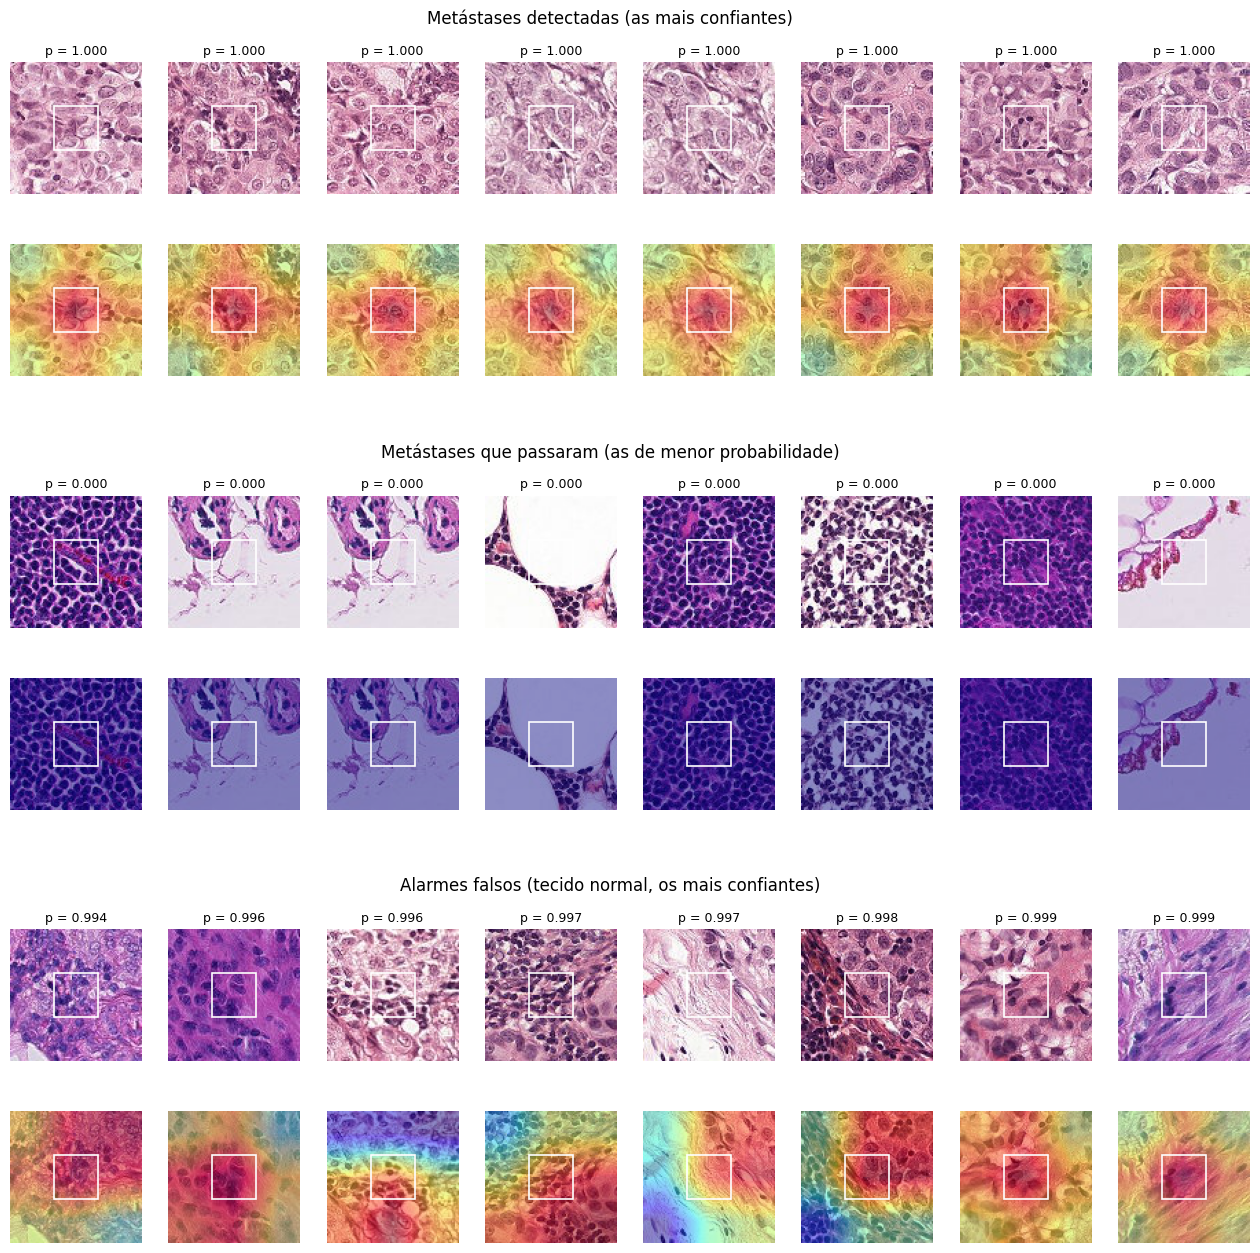

In [7]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

from src.dataset import preparar_lote
from src.interpretacao import grad_cam

modelos = [carregar_modelo(s) for s in sementes]

def mapas_do_ensemble(indices):
    x = preparar_lote(torch.from_numpy(np.array(X_teste[indices])).cuda(), aumento=False)
    return torch.stack([grad_cam(m, x, m.rede.layer4) for m in modelos]).mean(dim=0).cpu().numpy()

limiar = congeladas["limiar_logit"]
pos, neg = np.where(positivos)[0], np.where(negativos)[0]
pos_ordenados = pos[np.argsort(logits_final_teste[pos])]
neg_ordenados = neg[np.argsort(logits_final_teste[neg])]
grupos = {
    "Metástases detectadas (as mais confiantes)": pos_ordenados[-8:],
    "Metástases que passaram (as de menor probabilidade)": pos_ordenados[:8],
    "Alarmes falsos (tecido normal, os mais confiantes)": neg_ordenados[-8:],
}

fig = plt.figure(figsize=(16, 13))
for faixa, (titulo, indices) in zip(fig.subfigures(3, 1), grupos.items()):
    faixa.suptitle(titulo, fontsize=12)
    mapas = mapas_do_ensemble(indices)
    eixos = faixa.subplots(2, 8)
    for coluna, (i, mapa) in enumerate(zip(indices, mapas)):
        for linha, sobrepor in enumerate((False, True)):
            ax = eixos[linha, coluna]
            ax.imshow(X_teste[i])
            if sobrepor:
                ax.imshow(mapa, cmap="jet", alpha=0.45, vmin=0, vmax=1)
            ax.add_patch(Rectangle((31.5, 31.5), 32, 32, fill=False, edgecolor="white", linewidth=1.2))
            ax.axis("off")
        eixos[0, coluna].set_title(f"p = {sigmoide(logits_final_teste[i]):.3f}", fontsize=9)
fig.savefig(REPORTS_DIR / "figures" / "04_grad_cam.png", dpi=150, bbox_inches="tight")
plt.show()

**Resultado no teste (aberto uma vez).** Todas as expectativas do pré-registro se confirmaram: AUC **0,951** (validação: 0,967), sensibilidade **0,911** e especificidade **0,829** no limiar escolhido. Ensemble + TTA superou o modelo único (0,939) e a CNN pequena do notebook 02 (0,932). Todos os modelos caíram ~0,02 da validação para o teste — treino e validação da PCam são lâminas distintas, mas vêm do mesmo conjunto de treino do Camelyon16; o teste vem do conjunto de teste do desafio, coletado à parte. Com o limiar padrão de 0,5, a sensibilidade seria de só 0,690: a escolha do limiar pela validação foi o que manteve o modelo útil como triagem.

In [8]:
def medir_mapas(indices, tamanho_lote=256):
    """Para cada imagem: fração da evidência no centro, fração sobre pixels brancos e fração de pixels brancos."""
    no_centro, no_branco, area_branca = [], [], []
    for inicio in range(0, len(indices), tamanho_lote):
        lote = indices[inicio:inicio + tamanho_lote]
        mapas = mapas_do_ensemble(lote)                        # (b, 96, 96)
        branco = np.array(X_teste[lote]).mean(axis=3) > 220    # mesma definição do notebook 01
        total = mapas.sum(axis=(1, 2)) + 1e-8
        no_centro.append(mapas[:, 32:64, 32:64].sum(axis=(1, 2)) / total)
        no_branco.append((mapas * branco).sum(axis=(1, 2)) / total)
        area_branca.append(branco.mean(axis=(1, 2)))
    return [np.concatenate(v) for v in (no_centro, no_branco, area_branca)]

previsto = logits_final_teste >= limiar
sorteio = np.random.default_rng(0)
grupos_medidos = {
    "Metástases detectadas": np.where(previsto & positivos)[0],
    "Alarmes falsos": np.where(previsto & negativos)[0],
}
for nome, indices in grupos_medidos.items():
    amostra = sorteio.choice(indices, size=min(2000, len(indices)), replace=False)
    centro, sobre_branco, area_branca = medir_mapas(amostra)
    print(f"{nome} ({len(amostra)} imagens):")
    print(f"  evidência no quadrado central: média {centro.mean():.3f} (mapa uniforme: 0.111)")
    print(f"  evidência sobre fundo branco:  média {sobre_branco.mean():.3f} | "
          f"área branca da imagem: média {area_branca.mean():.3f}")

Metástases detectadas (2000 imagens):
  evidência no quadrado central: média 0.132 (mapa uniforme: 0.111)
  evidência sobre fundo branco:  média 0.097 | área branca da imagem: média 0.126
Alarmes falsos (2000 imagens):
  evidência no quadrado central: média 0.072 (mapa uniforme: 0.111)
  evidência sobre fundo branco:  média 0.109 | área branca da imagem: média 0.263


**Grad-CAM: onde está a evidência de metástase.** A última camada convolucional da ResNet-18 tem resolução 3×3; a célula central corresponde quase exatamente ao quadrado de 32×32 que define o rótulo. Mapas do ensemble (média dos 3 modelos), em 2.000 imagens de cada grupo, no limiar escolhido:

| Grupo | Evidência no quadrado central | Evidência sobre fundo branco | Área branca da imagem |
| --- | --- | --- | --- |
| Metástases detectadas | 0,132 | 0,097 | 0,126 |
| Alarmes falsos | 0,072 | 0,109 | 0,263 |
| *Mapa uniforme* | *0,111* | — | — |

- **A rede não privilegia o centro:** a evidência nas metástases detectadas fica só um pouco acima do uniforme. Ela aprendeu "tecido com cara de tumor no patch", não "tumor no centro" — o que explica parte dos alarmes falsos, cuja evidência fica **fora** do centro (tecido suspeito na borda, centro normal). As 8 imagens mais confiantes da figura, todas centradas, não representam o conjunto.
- **O atalho do fundo branco não aparece:** a evidência sobre o branco é menor que a área branca nos dois grupos (nos alarmes falsos, menos da metade).
- **As metástases que passaram** com probabilidade perto de zero não têm evidência em lugar nenhum; várias têm o quadrado central quase vazio (rótulos vindos de contornos grosseiros) ou só linfócitos.
- **Limitações:** a resolução 3×3 e a ampliação suavizada aproximam os valores absolutos (vale o contraste entre os grupos); o Grad-CAM aqui mostra a evidência **a favor** de metástase, não a evidência contra.
- **Melhoria possível:** dar mais peso ao centro (recorte da entrada ou pooling ponderado pela posição).

In [9]:
import json

MODELS_DIR = RAIZ / "models"
with open(MODELS_DIR / "decisoes_pre_teste.json", encoding="utf-8") as arquivo:
    congeladas = json.load(arquivo)  # as decisões vêm do arquivo, como na célula do teste
sementes = congeladas["sementes"]
modelos = [carregar_modelo(s) for s in sementes]

import hashlib

caminho_pesos = MODELS_DIR / "pcam_resnet18_ensemble.pt"
if caminho_pesos.exists():
    print("O modelo final já foi salvo (e publicado na Release v1.0): nada é regravado.")
else:
  # 1. Os 3 modelos (float16) e as decisões num arquivo só
  pacote = {
      "arquitetura": "ResNetPCam (src/modelos.py): ResNet-18 com saída única (logit)",
      "sementes": sementes,
      "pesos": [{nome: (t.half() if t.is_floating_point() else t) for nome, t in m.state_dict().items()}
                for m in modelos],
      "decisoes": congeladas,
  }
  caminho_pesos = MODELS_DIR / "pcam_resnet18_ensemble.pt"
  torch.save(pacote, caminho_pesos)
  sha256 = hashlib.sha256(caminho_pesos.read_bytes()).hexdigest()
  tamanho_mb = caminho_pesos.stat().st_size / 1e6
  print(f"{caminho_pesos.name}: {tamanho_mb:.1f} MB | sha256 {sha256[:16]}...")

  # 2. Conferência: recarregar e recalcular a AUC de validação (ensemble sem TTA: era 0.9636)
  recarregado = torch.load(caminho_pesos, map_location="cuda", weights_only=True)
  recarregados = []
  for pesos in recarregado["pesos"]:
      m = ResNetPCam(pretreinada=False).cuda()
      m.load_state_dict(pesos)  # converte de float16 para float32 ao copiar
      recarregados.append(m.eval())
  logits_conferencia = np.mean([prever(m, carregador_valid)[0] for m in recarregados], axis=0)
  print(f"AUC de validação, ensemble recarregado (sem TTA): {roc_auc_score(y_valid, logits_conferencia):.4f}")

  # 3. Metadados (este JSON vai para o repositório)
  with open(REPORTS_DIR / "04_resultado_teste.json", encoding="utf-8") as arquivo:
      teste = json.load(arquivo)
  no_limiar = teste["por_limiar"]["escolhido (sensib. 95% na validação)"]
  metadados = {
      "arquivo_pesos": caminho_pesos.name,
      "url_pesos": "https://github.com/davidfwallace/metastase-pcam/releases/download/v1.0/pcam_resnet18_ensemble.pt",
      "sha256": sha256,
      "tamanho_mb": round(tamanho_mb, 1),
      "arquitetura": pacote["arquitetura"],
      "treino": {
          "configuracao": FINAL, "sementes": sementes, "epocas": 3,
          "otimizador": "AdamW (lr 1e-4, weight decay 1e-4), agendamento cosseno",
          "aumento_de_dados": "8 simetrias do quadrado", "pre_treino": "ImageNet (torchvision IMAGENET1K_V1)",
      },
      "entrada": "imagem RGB 96x96, uint8; normalizada com média e desvio da ImageNet",
      "previsao": {"ensemble": congeladas["ensemble"], "tta": congeladas["tta"]},
      "limiar_logit": congeladas["limiar_logit"],
      "limiar_probabilidade": congeladas["limiar_probabilidade"],
      "validacao": {"auc": congeladas["auc_valid"], "sensibilidade_alvo": congeladas["sensibilidade_alvo_valid"]},
      "teste": {"auc": teste["combinacoes"]["Ensemble + TTA (modelo final)"]["auc"],
                "sensibilidade": no_limiar["sensibilidade"], "especificidade": no_limiar["especificidade"]},
      "avisos": [
          "As probabilidades não são calibradas: use o limiar, não a probabilidade ao pé da letra.",
          "Projeto de estudo. Não é um dispositivo médico e não deve ser usado em diagnóstico.",
      ],
  }
  with open(MODELS_DIR / "metadados.json", "w", encoding="utf-8") as arquivo:
      json.dump(metadados, arquivo, indent=2, ensure_ascii=False)
  print("Salvo: models/metadados.json")

O modelo final já foi salvo (e publicado na Release v1.0): nada é regravado.


In [10]:
import pandas as pd
from PIL import Image

X_teste_mm, y_teste = preparar_split(DATA_DIR, "test", CACHE_DIR)
logits_salvos = np.load(REPORTS_DIR / "04_logits_teste.npy")

# 16 imagens do teste, salvas como PNG (formato sem perdas)
indices = np.random.default_rng(1).choice(len(y_teste), size=16, replace=False)
pasta = Path("/content/amostras_teste")
pasta.mkdir(exist_ok=True)
for i in indices:
    Image.fromarray(np.array(X_teste_mm[i])).save(pasta / f"teste_{i:05d}.png")

execucao = subprocess.run([sys.executable, "-m", "src.prever", str(pasta), "--saida", "/content/previsoes.csv"],
                          cwd=REPO, capture_output=True, text=True)
print(execucao.stdout[-600:] if execucao.returncode == 0 else execucao.stderr)

previsoes = pd.read_csv("/content/previsoes.csv")
previsoes["indice"] = previsoes["arquivo"].str.extract(r"(\d+)", expand=False).astype(int)
previsoes["logit_notebook"] = logits_salvos[previsoes["indice"]]
diferenca = (previsoes["logit"] - previsoes["logit_notebook"]).abs()
print(f"Maior diferença entre script e notebook: {diferenca.max():.4f} (logit)")

5                       0.9976                   True
teste_26958.png -4.4497                       0.0115                  False
teste_27120.png -7.4630                       0.0006                  False
teste_28471.png -6.1691                       0.0021                  False
teste_31077.png -4.7404                       0.0087                  False
teste_31133.png -4.2429                       0.0142                  False

8 de 16 imagens com suspeita (limiar: logit -3.415, escolhido para sensibilidade de 95% na validação). Dispositivo: cuda. Resultado salvo em /content/previsoes.csv.

Maior diferença entre script e notebook: 0.0088 (logit)


## Conclusões

**Modelo final:** ensemble de 3 ResNet-18 pré-treinadas (`C_fine_tuning_3ep`, sementes 0–2, última época), com TTA nas 8 simetrias do quadrado e limiar escolhido para sensibilidade de 95% na validação. Todas as decisões foram tomadas na validação e congeladas em `models/decisoes_pre_teste.json` antes de o teste ser aberto, uma única vez.

**Resultado no teste (32.768 imagens):**

| Métrica | Validação | Teste |
| --- | --- | --- |
| AUC | 0,967 | **0,951** |
| Sensibilidade (limiar escolhido) | 0,950 | **0,911** |
| Especificidade (limiar escolhido) | 0,819 | **0,829** |
| Sensibilidade com limiar 0,5 | 0,799 | 0,690 |

**Todas as expectativas do pré-registro se confirmaram**, incluindo a queda da validação para o teste e a superioridade do ensemble + TTA (0,951) sobre o modelo único (0,939) e sobre a CNN pequena do notebook 02 (0,932). Ensemble e TTA renderam mais no teste do que na validação (+0,012 contra +0,008).

**O limiar importa mais que qualquer ajuste fino de modelo.** Com o limiar padrão de 0,5, o modelo deixaria passar 31% das metástases no teste; com o limiar escolhido pela validação, 9%.

**Grad-CAM.** A rede usa tecido, não fundo branco: a evidência sobre o branco é menor que a área branca, e o atalho visto no notebook 01 não aparece. Mas ela não privilegia o quadrado central que define o rótulo, e parte dos alarmes falsos tem a evidência **fora** do centro (tecido suspeito na borda, centro normal).

**Limitações:**
- **Probabilidades não calibradas** (log-loss 0,48 no teste): o modelo deve ser usado como ordenador com limiar, não pelas probabilidades.
- **O intervalo de confiança é otimista:** o bootstrap sorteia imagens, mas imagens da mesma lâmina são parecidas (há patches quase idênticos no teste).
- **Rótulos grosseiros:** parte das metástases não detectadas tem o quadrado central quase vazio — herança dos contornos das anotações originais.
- **Um único conjunto de dados:** o desempenho em lâminas de outro laboratório não foi medido.
- **Projeto de estudo:** não é um dispositivo médico.

**Trabalhos futuros:** dar mais peso ao centro (recorte da entrada ou pooling ponderado pela posição); calibrar as probabilidades na validação (temperature scaling); bootstrap por lâmina, se os metadados originais da PCam trouxerem a lâmina de cada patch; redes com equivariância a rotações, como no artigo original da PCam.

**Para usar o modelo:** `python -m src.prever <imagens ou pastas>` — baixa os pesos da Release v1.0 na primeira execução e confere o SHA-256.